**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Aarón Hernández Jiménez
*   MATRÍCULA: A01642529

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [2]:
loan_df = pd.read_csv('personal_loan.csv')
loan_df = loan_df.set_index('ID')
loan_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   str    
 9   Securities Account  5037 non-null   str    
 10  CD Account          5037 non-null   str    
 11  Online              5037 non-null   str    
 12  CreditCard          5037 non-null   str    
dtypes: float64(2), int64(6), str(5)
memory usage: 511.7 KB


son 5037 registros y 13 columnas sin contar el ID que ya quedo como indice, ninguna columna tiene nulos

hay 8 numericas, 6 int64 (Age, Experience, Income, ZIP Code, Family y Mortgage) y 2 float64 (CCAvg y Education), y 5 de texto (Personal Loan, Securities Account, CD Account, Online y CreditCard), en pandas 3 salen como str y en colab con pandas 2 salen como object

desde aqui ya se ven dos cosas raras, Education deberia ser entero porque solo tiene 1, 2 o 3 y salio float, o sea que hay algun valor con decimales, y las binarias salieron como texto, entonces no todo lo que tienen adentro son 0 y 1

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [3]:
n_inicial = len(loan_df)
loan_df.describe()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000
mean,45.411356,20.122494,73.898352,93152.865595,2.394679,1.942404,1.880941,56.500695
std,11.646805,11.461278,46.130504,2119.637960,1.151145,1.755954,0.843337,101.657580
min,23.000000,-3.000000,8.000000,9307.000000,-3.000000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000
50%,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.600000,3.000000,101.000000
max,144.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,7.300000,635.000000


revisando el minimo y el maximo de cada columna salen varios valores que no pueden ser:

- Age tiene maximo de 144 años cuando el 75% de los clientes tiene 55 o menos
- Experience tiene minimo de -3 y no puedes tener años de experiencia negativos
- Family tiene minimo de -3 y una familia es de minimo 1, que es el mismo cliente
- Education tiene un 7.3 cuando solo existen los codigos 1, 2 y 3
- ZIP Code tiene un 9307 que es de 4 digitos y los codigos postales de estados unidos son de 5

Income (8 a 224), CCAvg (0 a 10) y Mortgage (0 a 635) se ven bien, el 0 en Mortgage nada mas es que no tiene hipoteca y en CCAvg que no uso la tarjeta

In [4]:
loan_df[loan_df['Age'] > 100]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


son 3 clientes con 123, 144 y 130 años, no son posibles porque la persona mas vieja registrada llego a 122 y sin ellos la edad maxima del dataset es 67, ademas no cuadran con su experiencia, si le restas Experience a Age saldria que empezaron a trabajar a los 84, 138 y 123 años, asi que se eliminan

In [5]:
loan_df = loan_df[loan_df['Age'] <= 100]

In [6]:
exp_negativa = loan_df['Experience'] < 0
familia_invalida = loan_df['Family'] < 1
educacion_invalida = ~loan_df['Education'].isin([1, 2, 3])
zip_invalido = loan_df['ZIP Code'] < 10000

print('Experience negativa:', exp_negativa.sum(), loan_df.loc[exp_negativa, 'Experience'].value_counts().to_dict())
print('Edades con Experience negativa:', loan_df.loc[exp_negativa, 'Age'].min(), 'a', loan_df.loc[exp_negativa, 'Age'].max())
loan_df[familia_invalida | educacion_invalida | zip_invalido]

Experience negativa: 53 {-1: 34, -2: 15, -3: 4}
Edades con Experience negativa: 23 a 29


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
15,60,30,22,95054,-1,1.5,3.0,0,0,No,0,Yes,Yes
347,25,0,43,94305,2,1.6,7.3,0,0,Yes,Yes,1,Yes
384,51,25,21,9307,4,0.6,3.0,0,No,0,0,1,Yes
3000,40,14,164,94720,-3,4.3,2.0,0,1,No,No,No,No


Experience negativa: son 53 registros con -1, -2 y -3, no puedes tener experiencia negativa, todos tienen entre 23 y 29 años entonces parece error de captura de gente que apenas empezaba a trabajar, no quise nada mas quitarles el signo porque no sabemos que significaba y meteriamos datos inventados que se ven normales, asi que se eliminan

Family menor a 1: son 2 registros con -1 y -3, el numero de integrantes incluye al cliente entonces lo minimo es 1

Education con 7.3: es 1 registro, solo puede ser 1, 2 o 3 y ni siquiera es entero, por este valor pandas leyo toda la columna como float

ZIP Code 9307: es 1 registro, es el unico de 4 digitos y todos los demas son de 5 y de california (90xxx a 96xxx), a lo mejor era 93007 y se perdio un digito pero no hay forma de confirmarlo

In [7]:
loan_df = loan_df[~(exp_negativa | familia_invalida | educacion_invalida | zip_invalido)]

In [8]:
loan_df[loan_df['CCAvg'] * 12 > loan_df['Income']]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
2,39,15,11,94720,1,1.00,1.0,0,0,0,0,0,0
50,32,8,8,92093,4,0.70,2.0,0,0,Yes,No,Yes,0
110,41,14,9,91330,3,1.00,2.0,0,0,0,0,No,0
291,43,16,8,90089,3,0.67,2.0,88,0,0,0,Yes,0
933,50,23,9,92064,2,1.00,2.0,0,0,No,No,Yes,0
1000,59,35,8,92691,4,0.70,1.0,91,0,Yes,No,0,0
1979,41,17,11,91330,1,1.00,1.0,0,0,0,0,No,No
2132,59,35,11,94949,2,1.00,1.0,0,No,0,No,No,Yes
2248,63,37,8,94618,1,0.80,2.0,97,0,No,0,1,No


tambien revise si CCAvg (gasto al mes) cuadraba con Income (ingreso al año), en 15 clientes lo que gastan con tarjeta en 12 meses es mas de lo que ganan al año, todos ganan entre 8 y 11 mil y gastan de 0.67 a 1 mil al mes, estos no los elimine porque si se puede gastar a credito mas de lo que ganas, con deudas, ahorros o con el ingreso de alguien mas de la familia, es raro pero no imposible

In [9]:
eliminados = n_inicial - len(loan_df)
print(f'Registros eliminados: {eliminados} de {n_inicial} ({eliminados / n_inicial:.2%})')
print('Registros restantes:', len(loan_df))

Registros eliminados: 60 de 5037 (1.19%)
Registros restantes: 4977


en total se eliminaron 60 registros, 3 por edad, 53 por experiencia negativa, 2 por familia, 1 por educacion y 1 por codigo postal, eso es el 1.19% de los 5037 que habia al inicio y quedan 4977

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [10]:
loan_df.describe(exclude='number')

,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4977,4977,4977,4977,4977
unique,4,4,4,4,4
top,0,No,No,Yes,0
freq,3475,2693,2462,1700,2628


In [11]:
for col in loan_df.select_dtypes(exclude='number').columns:
    print(loan_df[col].value_counts(), '\n')

Personal Loan
0      3475
No     1017
Yes     368
1       117
Name: count, dtype: int64 

Securities Account
No     2693
0      1765
Yes     390
1       129
Name: count, dtype: int64 

CD Account
No     2462
0      2212
1       163
Yes     140
Name: count, dtype: int64 

Online
Yes    1700
No     1628
1      1275
0       374
Name: count, dtype: int64 

CreditCard
0      2628
Yes     907
No      885
1       557
Name: count, dtype: int64 



las 5 columnas de texto tienen 4 valores unicos cuando deberian ser 2, el mismo dato esta escrito como 0 y 1 guardados como texto y tambien como No y Yes, por ejemplo en Personal Loan hay 3475 de '0', 1017 de 'No', 368 de 'Yes' y 117 de '1', segun la descripcion 1 es si y 0 es no, entonces Yes pasa a 1 y No pasa a 0

In [12]:
bin_cols = ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']
binario = {'0': 0, '1': 1, 'No': 0, 'Yes': 1}
for col in bin_cols:
    loan_df[col] = loan_df[col].map(binario)

loan_df[bin_cols].apply(pd.Series.value_counts)

,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,4492,4458,4674,2002,3513
1,485,519,303,2975,1464


ya quedaron las 5 columnas solo con 0 y 1, en cada columna los dos conteos suman 4977 asi que no se quedo ningun valor sin convertir, si hubiera alguno raro como 'yes' en minusculas map lo hubiera dejado como NaN y se notaria en la suma

4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [13]:
print('Registros duplicados:', loan_df.duplicated().sum())
print('ID mínimo de las copias:', loan_df[loan_df.duplicated()].index.min())
loan_df[loan_df.duplicated(keep=False)].sort_values(list(loan_df.columns)).head(6)

Registros duplicados: 36
ID mínimo de las copias: 5000


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
1160,28,1,40,95134,1,2.0,2.0,0,0,1,0,1,0
5031,28,1,40,95134,1,2.0,2.0,0,0,1,0,1,0
3673,34,9,65,95134,4,1.3,1.0,0,0,0,0,0,1
5032,34,9,65,95134,4,1.3,1.0,0,0,0,0,0,1
2101,35,5,203,95032,1,10.0,3.0,0,1,0,0,0,0
5020,35,5,203,95032,1,10.0,3.0,0,1,0,0,0,0


hay 36 registros duplicados, tienen los mismos valores en las 13 columnas pero diferente ID, como el ID es el indice duplicated() solo compara el contenido de las filas y esta bien que sea asi, es casi imposible que dos clientes reales coincidan al mismo tiempo en edad, experiencia, ingreso, codigo postal, gasto, hipoteca y los 5 productos del banco

todas las copias tienen ID de 5000 para arriba, o sea que son filas que se pegaron al final del archivo despues de los clientes del 0 al 4999, en el archivo habia 37 copias pero la del ID 5003 era copia de un registro con experiencia negativa y ya se habia eliminado en la pregunta 2, de cada uno se queda la primera vez que aparece

In [14]:
loan_df = loan_df.drop_duplicates().reset_index(drop=True)
print(loan_df.shape)
loan_df.index

(4941, 13)


RangeIndex(start=0, stop=4941, step=1)

quedan 4941 registros con el indice de 0 a 4940 sin saltos, use drop=True porque el ID solo servia para identificar al cliente y no aporta nada al analisis, si lo dejaba como columna se iba a contar como otra variable numerica en num_cols

5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [15]:
# En pandas 3, astype(str) produce el tipo 'str'; astype(object) asegura el tipo object solicitado
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype(str).astype(object)
# Primero a entero para que las categorías sean 1, 2, 3 y no 1.0, 2.0, 3.0
loan_df['Education'] = loan_df['Education'].astype(int).astype(pd.CategoricalDtype(categories=[1, 2, 3], ordered=True))
loan_df[bin_cols] = loan_df[bin_cols].astype('category')
loan_df.dtypes

Age                      int64
Experience               int64
Income                   int64
ZIP Code                object
Family                   int64
CCAvg                  float64
Education             category
Mortgage                 int64
Personal Loan         category
Securities Account    category
CD Account            category
Online                category
CreditCard            category
dtype: object

In [16]:
num_cols = loan_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = loan_df.select_dtypes(include=['object', 'category']).columns.tolist()
print('num_cols:', num_cols)
print('cat_cols:', cat_cols)

num_cols: ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
cat_cols: ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


con las conversiones cada variable queda con el tipo que le toca segun lo que realmente es

numericas (num_cols), son 6: Income, CCAvg y Mortgage son continuas porque son montos en miles de dolares, Age, Experience y Family son discretas porque son conteos de años o de personas, pero sus valores tienen orden y distancia entre ellos entonces se analizan como numericas

categoricas (cat_cols), son 7: ZIP Code es nominal, aunque son numeros no tiene sentido promediarlos, Education es ordinal porque 1 < 2 < 3, y las 5 binarias solo dicen si el cliente tiene o no el producto, o en Personal Loan si acepto el prestamo

# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [17]:
estadisticas = loan_df[num_cols].describe().T
estadisticas['skew'] = loan_df[num_cols].skew()
estadisticas['kurtosis'] = loan_df[num_cols].kurt()
estadisticas

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Age,4941.0,45.560210,11.315617,24.0,36.0,46.0,55.0,67.0,-0.022754,-1.161599
Experience,4941.0,20.335357,11.308351,0.0,11.0,20.0,30.0,43.0,-0.015216,-1.134857
Income,4941.0,73.826553,46.106768,8.0,39.0,64.0,98.0,224.0,0.841991,-0.046164
Family,4941.0,2.391621,1.148244,1.0,1.0,2.0,3.0,4.0,0.159463,-1.403842
CCAvg,4941.0,1.935855,1.748406,0.0,0.7,1.5,2.6,10.0,1.594670,2.635545
Mortgage,4941.0,56.663631,101.875349,0.0,0.0,0.0,101.0,635.0,2.103865,4.760021


pandas calcula skew() y kurt() con correccion de muestra, y kurt() da la curtosis en exceso (de fisher) donde la normal vale 0, los criterios que use:

- asimetria: si el valor absoluto es menor a 0.5 es mas o menos simetrica, entre 0.5 y 1 es moderada y arriba de 1 es alta, el signo dice para donde va la cola, positivo es a la derecha
- curtosis: cerca de 0 es mesocurtica como la normal, negativa es platicurtica (mas plana y con colas ligeras) y positiva es leptocurtica (mas picuda y con colas pesadas)

Age tiene asimetria de -0.02 y curtosis de -1.16, es simetrica y platicurtica, los clientes estan repartidos casi parejo entre 24 y 67 años

Income tiene 0.84 y -0.05, es asimetrica positiva moderada y mesocurtica

Mortgage tiene 2.10 y 4.76, es asimetrica positiva alta y leptocurtica, casi todos tienen 0 y unos pocos tienen hipotecas muy grandes

7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

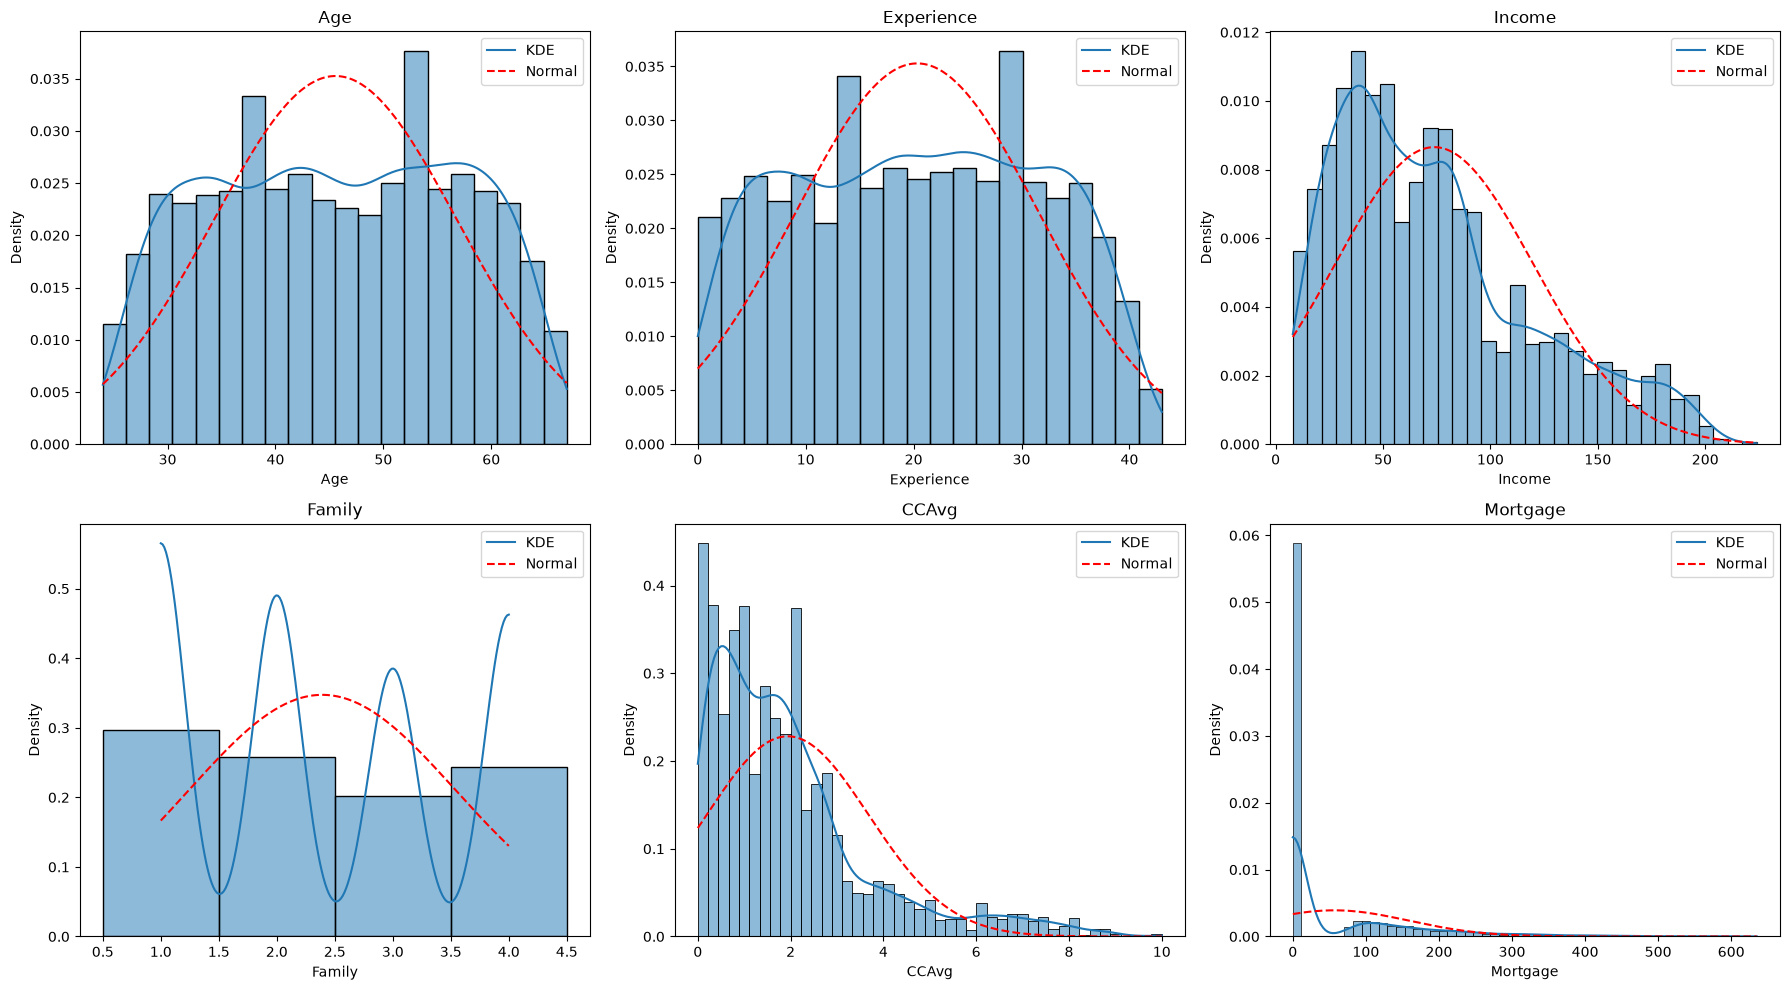

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for col, ax in zip(num_cols, axes.flat):
    sns.histplot(loan_df[col], stat='density', kde=True, discrete=(col == 'Family'), line_kws={'label': 'KDE'}, ax=ax)
    x = np.linspace(loan_df[col].min(), loan_df[col].max(), 200)
    ax.plot(x, norm.pdf(x, loan_df[col].mean(), loan_df[col].std()), color='red', linestyle='--', label='Normal')
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

Age se ve plano sin un pico en medio, la KDE queda abajo de la normal en el centro y arriba en las orillas, coincide con la asimetria casi en 0 y la curtosis negativa (-1.16)

Income la mayoria gana entre 20 y 100 mil y tiene una cola larga a la derecha hasta 224 mil, el pico de la KDE esta a la izquierda del de la normal y eso coincide con la asimetria positiva moderada (0.84), que la curtosis salga casi en 0 no quiere decir que sea normal, la cola derecha es mas larga pero el centro es mas ancho y plano y una cosa compensa la otra

Mortgage la barra en 0 se come toda la grafica (el 69% no tiene hipoteca) y lo demas es una cola larga hasta 635 mil, la normal no se parece en nada a los datos y hasta pone densidad en valores negativos, coincide con la asimetria (2.10) y la curtosis (4.76) altas

en las tres la forma de la grafica confirma lo que salio en los numeros

en Family la KDE sale con 4 picos porque solo tiene valores del 1 al 4, ahi el histograma la explica mejor que una curva

In [19]:
loan_df[num_cols].agg(['mean', 'median']).T

,mean,median
Age,45.560210,46.0
Experience,20.335357,20.0
Income,73.826553,64.0
Family,2.391621,2.0
CCAvg,1.935855,1.5
Mortgage,56.663631,0.0


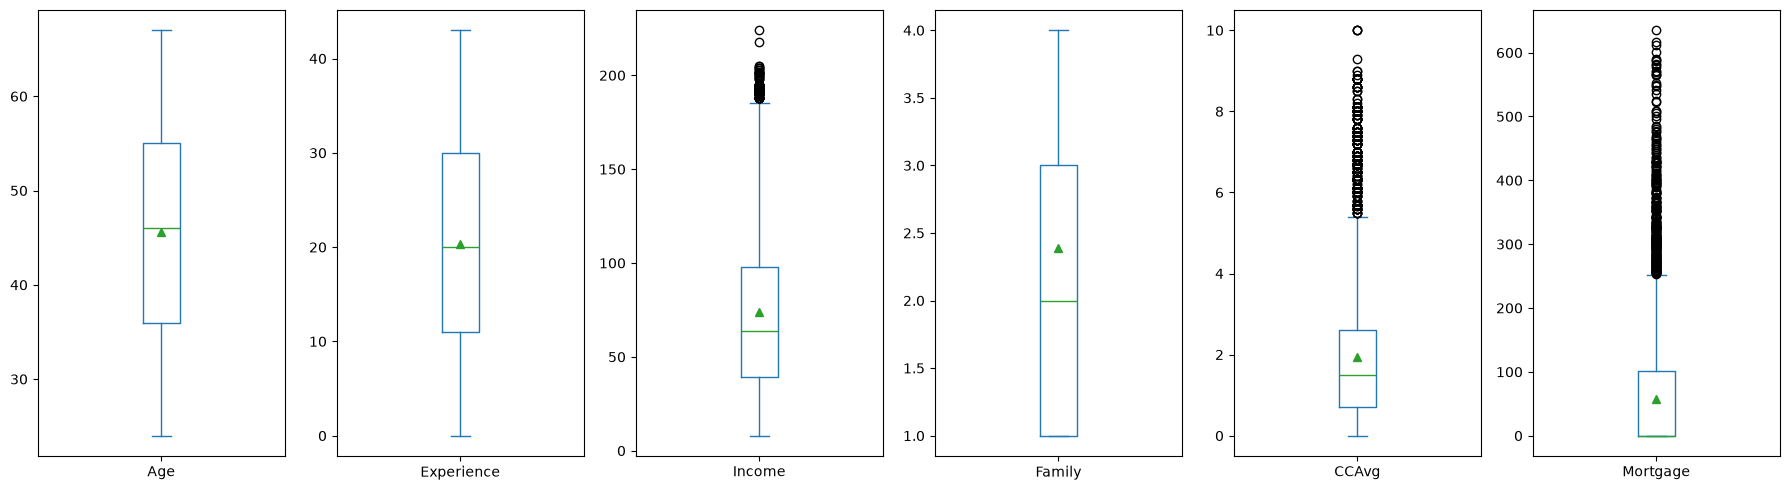

In [20]:
loan_df[num_cols].plot(kind='box', subplots=True, layout=(1, 6), figsize=(18, 5), showmeans=True)
plt.tight_layout()
plt.show()

media contra mediana: Age 45.56 y 46, Experience 20.34 y 20, Income 73.83 y 64, Family 2.39 y 2, CCAvg 1.94 y 1.5, Mortgage 56.66 y 0 (la media es el triangulo verde en cada boxplot)

la media se mueve con los valores extremos y la mediana no, entonces si la media queda arriba de la mediana es que hay valores altos jalandola y la distribucion tiene asimetria positiva (cola a la derecha), eso pasa en Income, CCAvg y sobre todo en Mortgage, en sus boxplots se ven un monton de atipicos arriba del bigote, en Mortgage la mediana es 0 porque mas de la mitad no tiene hipoteca

en Age y Experience la media y la mediana son casi iguales y la caja es simetrica, o sea que son distribuciones simetricas como ya decia su asimetria cercana a 0, Family tiene asimetria positiva leve (0.16) y por eso la media apenas pasa a la mediana

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [21]:
loan_df[cat_cols].describe()

,ZIP Code,Education,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4941,4941,4941,4941,4941,4941,4941
unique,467,3,2,2,2,2,2
top,94720,1,0,0,0,1,0
freq,163,2079,4462,4426,4640,2951,3489


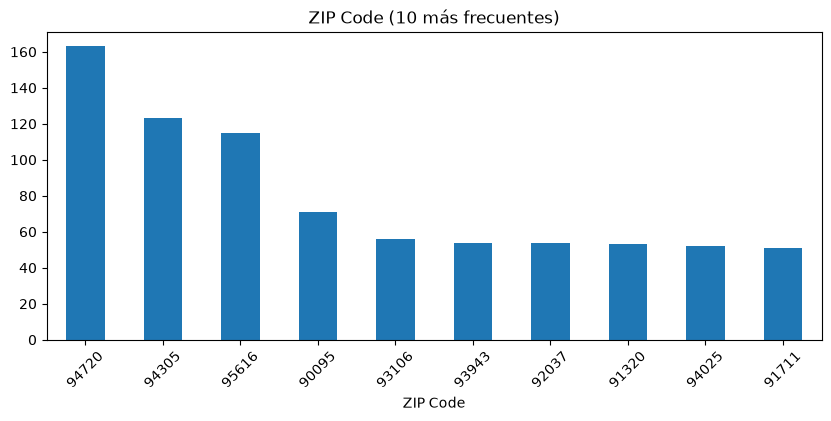

In [22]:
loan_df['ZIP Code'].value_counts().head(10).plot(kind='bar', figsize=(10, 4), rot=45, title='ZIP Code (10 más frecuentes)')
plt.show()

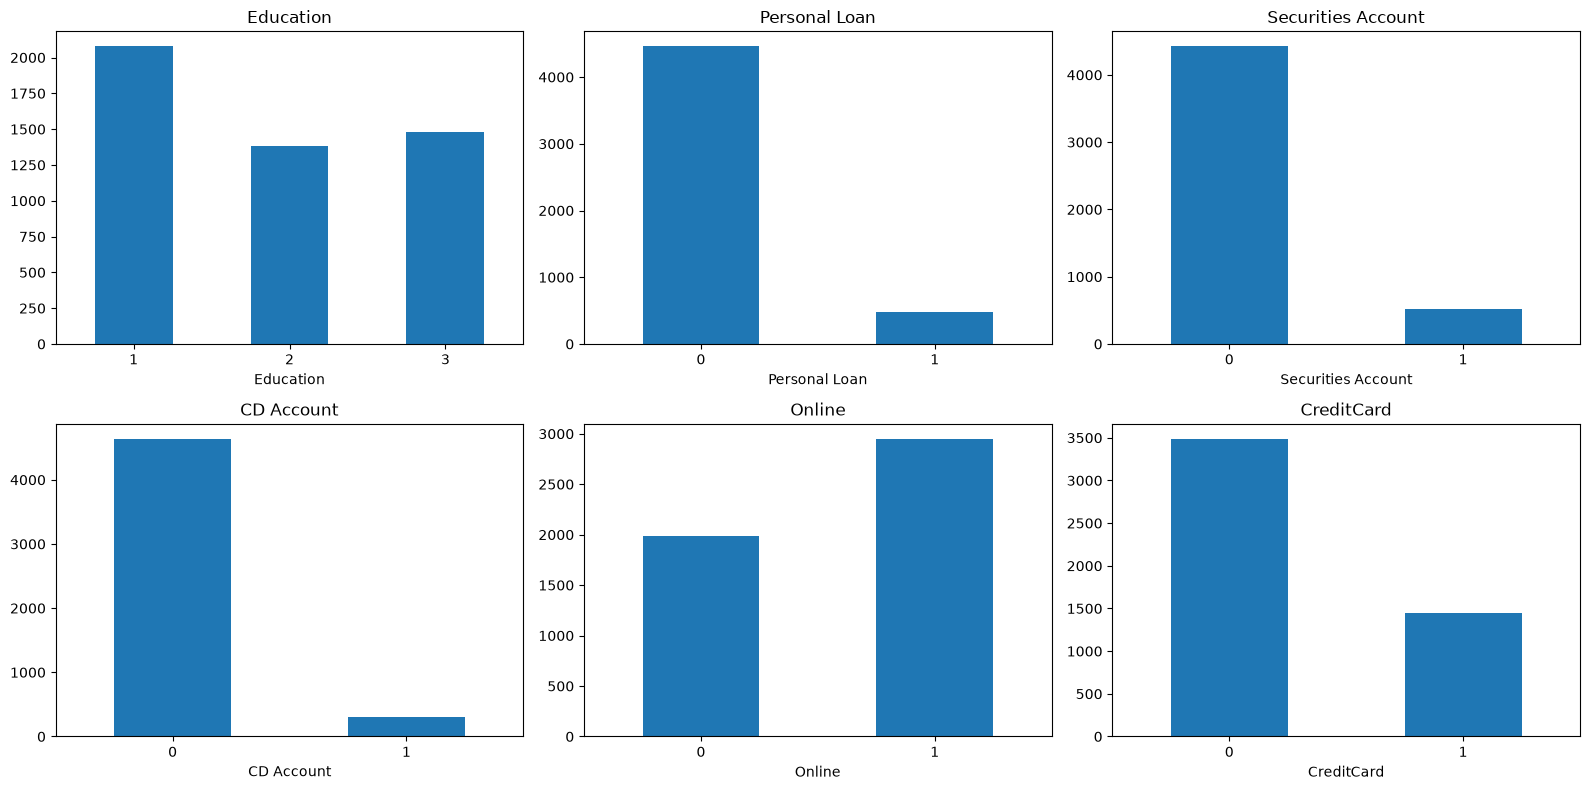

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for col, ax in zip([col for col in cat_cols if col != 'ZIP Code'], axes.flat):
    loan_df[col].value_counts().sort_index().plot(kind='bar', ax=ax, rot=0, title=col)
plt.tight_layout()
plt.show()

ZIP Code tiene alta cardinalidad, son 467 codigos distintos en 4941 registros, por eso solo grafique los 10 que mas salen, el mas comun es 94720 con 163 clientes y ninguno pasa del 3.3% de los registros

Education: el nivel 1 (graduado) es el mas comun con 2079 clientes (42.1%), el 2 y el 3 estan parejos con 28.0% y 29.9%

Personal Loan esta muy desbalanceada, solo 479 clientes (9.7%) aceptaron el prestamo, hay que tomarlo en cuenta cuando se haga el modelo

pocos tienen Securities Account (10.4%) o CD Account (6.1%), en cambio el 59.7% usa la banca en linea (Online) y el 29.4% tiene tarjeta de credito del banco (CreditCard)

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

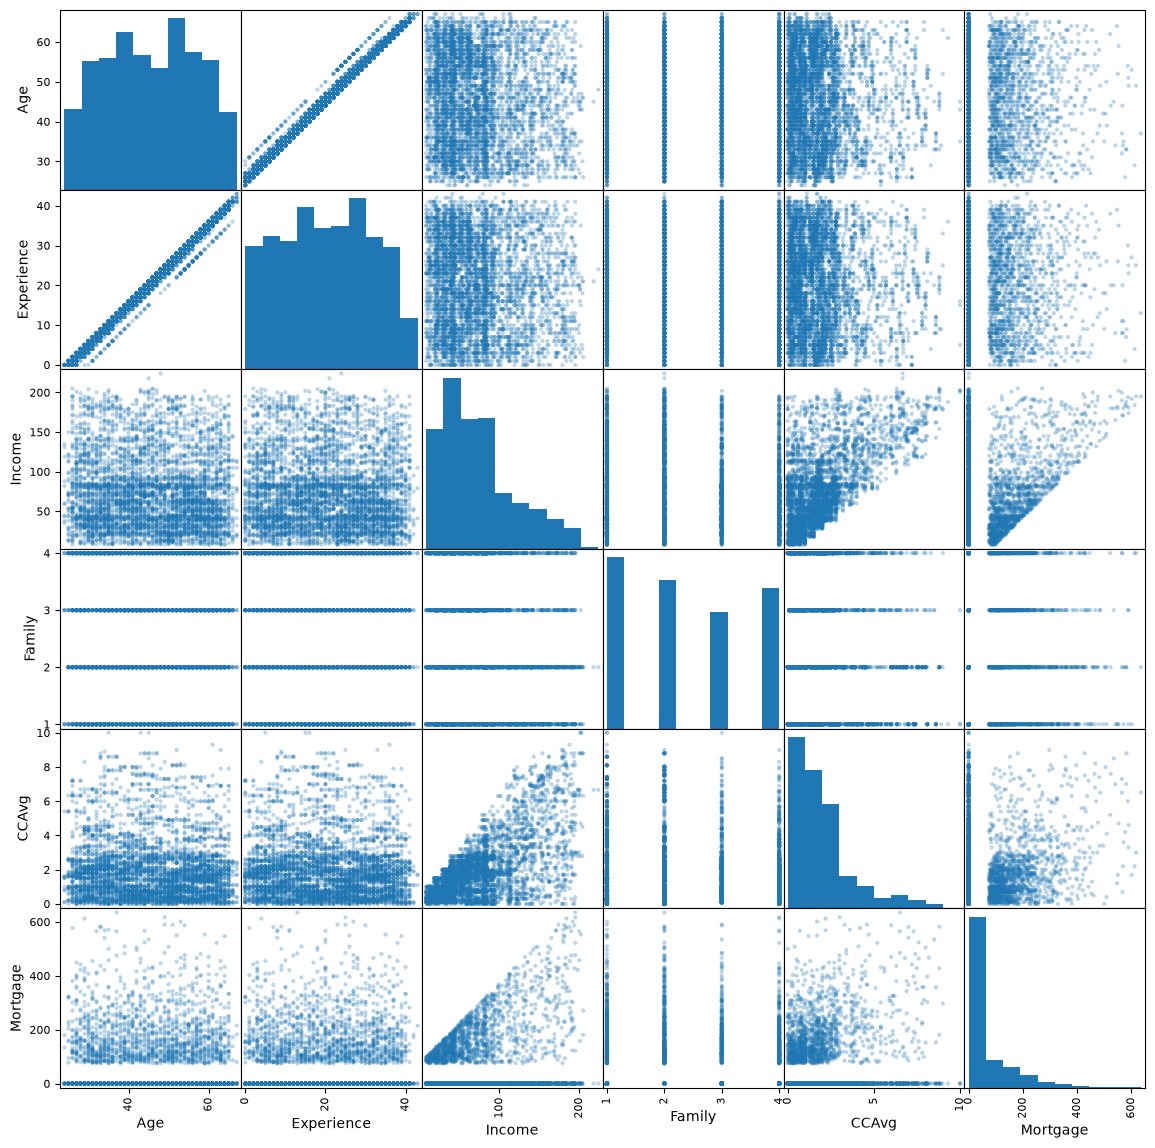

In [24]:
pd.plotting.scatter_matrix(loan_df[num_cols], figsize=(14, 14), alpha=0.3, diagonal='hist')
plt.show()

escogi el par Income y CCAvg, la relacion es positiva, entre mas ganas mas gastas al mes con la tarjeta, la nube tiene forma de abanico, con ingresos menores a 50 mil el gasto nunca pasa de 2.8 mil al mes y con ingresos altos se abre mucho (de 0 a 10 mil), o sea ganar mucho te deja gastar mas pero no te obliga, por eso espero una correlacion positiva de moderada a fuerte pero no perfecta

otras cosas que se ven:

- Age y Experience son casi una linea recta (varias rectas paralelas muy juntas) porque la experiencia sube al mismo ritmo que la edad
- Income con Mortgage tiene un limite en forma de triangulo parecido, las hipotecas grandes solo salen con ingresos altos, pero la mayoria de los puntos esta en la franja de 0 porque no tienen hipoteca
- las de Family salen en franjas porque solo tiene 4 valores, y lo demas son nubes sin tendencia

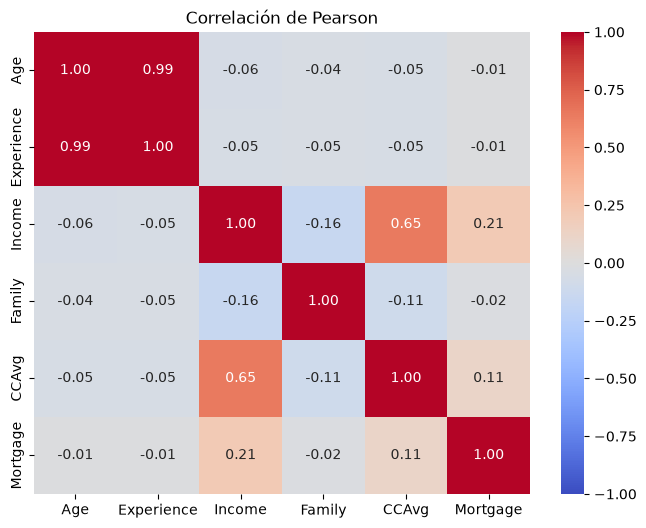

In [25]:
plt.figure(figsize=(8, 6))
sns.heatmap(loan_df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlación de Pearson')
plt.show()

la correlacion de pearson entre Income y CCAvg es 0.65, positiva y de moderada a fuerte como esperaba por la grafica, no llega a 1 porque entre mas ingreso mas se dispersa el gasto (el abanico), la mas alta del mapa es Age con Experience (0.99) que confirma la casi linea recta, luego Income con Mortgage (0.21), que sale baja aunque tenga el triangulo porque la mayoria no tiene hipoteca y se queda en 0 sin importar cuanto gane, todos los demas pares estan cerca de 0 (ninguno pasa de 0.16 en valor absoluto) y son las nubes sin tendencia

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


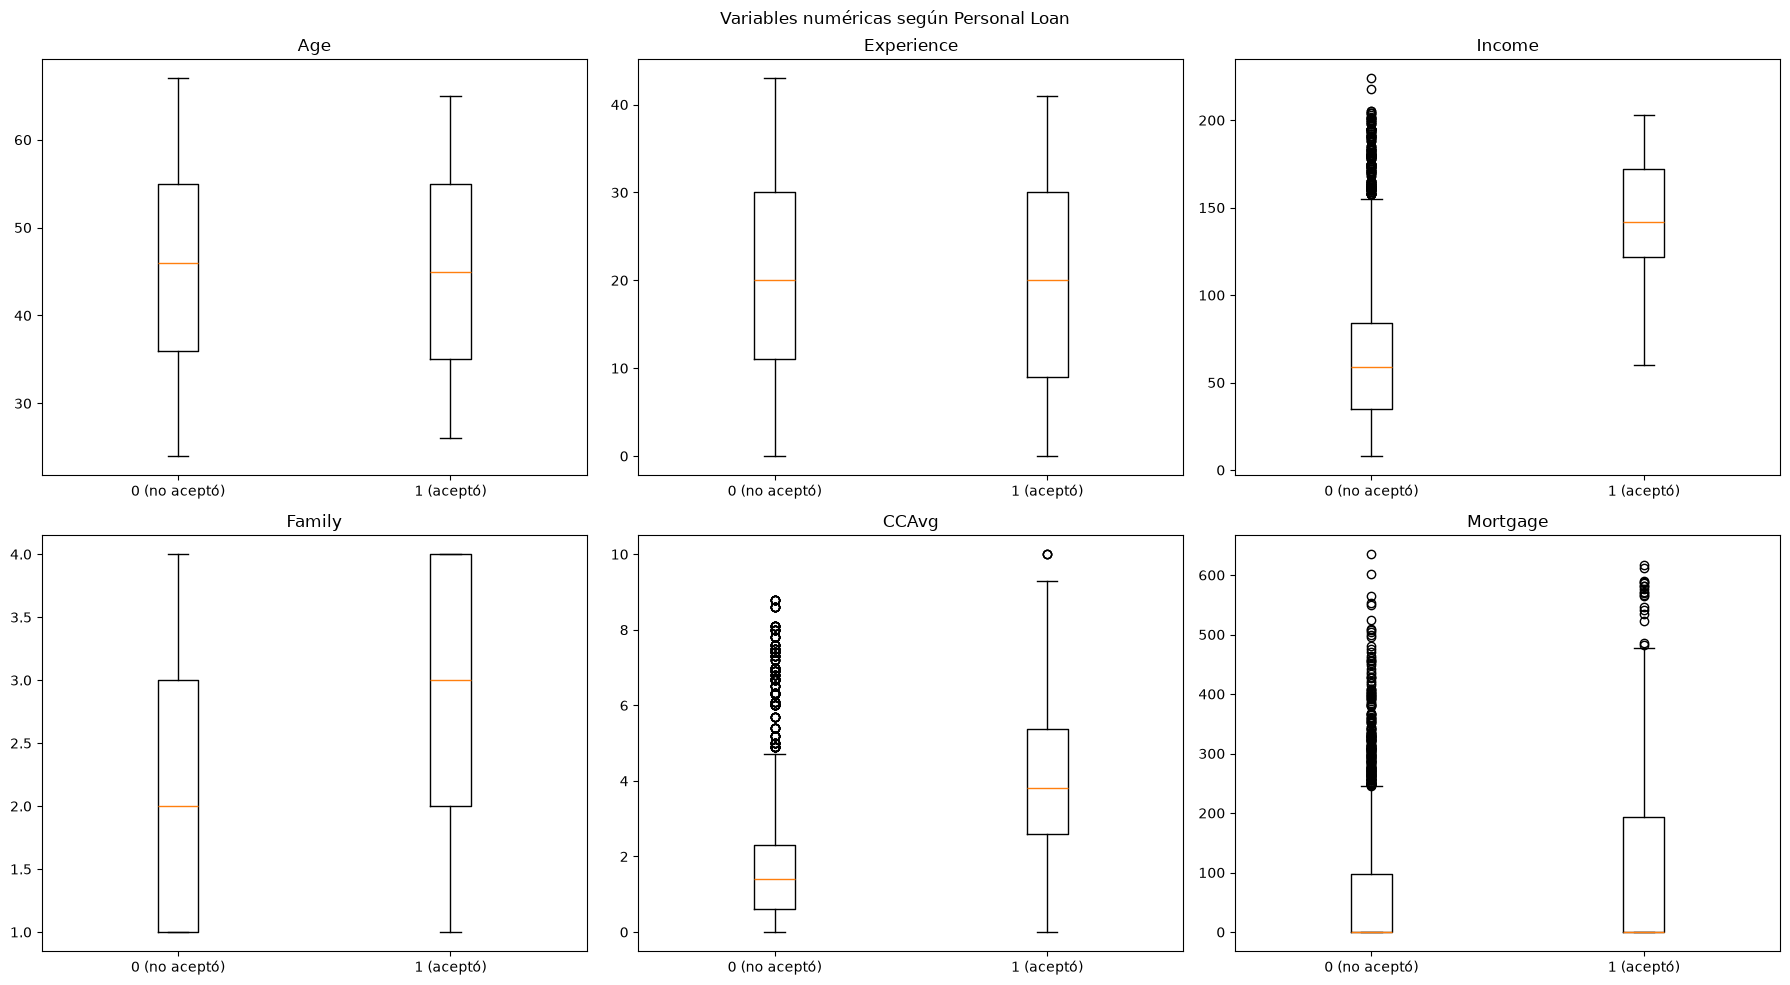

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for col, ax in zip(num_cols, axes.flat):
    ax.boxplot([loan_df.loc[loan_df['Personal Loan'] == 0, col], loan_df.loc[loan_df['Personal Loan'] == 1, col]])
    ax.set_xticks([1, 2], ['0 (no aceptó)', '1 (aceptó)'])
    ax.set_title(col)
plt.suptitle('Variables numéricas según Personal Loan')
plt.tight_layout()
plt.show()

In [27]:
loan_df.groupby('Personal Loan', observed=True)[num_cols].median()

,Age,Experience,Income,Family,CCAvg,Mortgage
Personal Loan,,,,,,
0,46.0,20.0,59.0,2.0,1.4,0.0
1,45.0,20.0,142.0,3.0,3.8,0.0


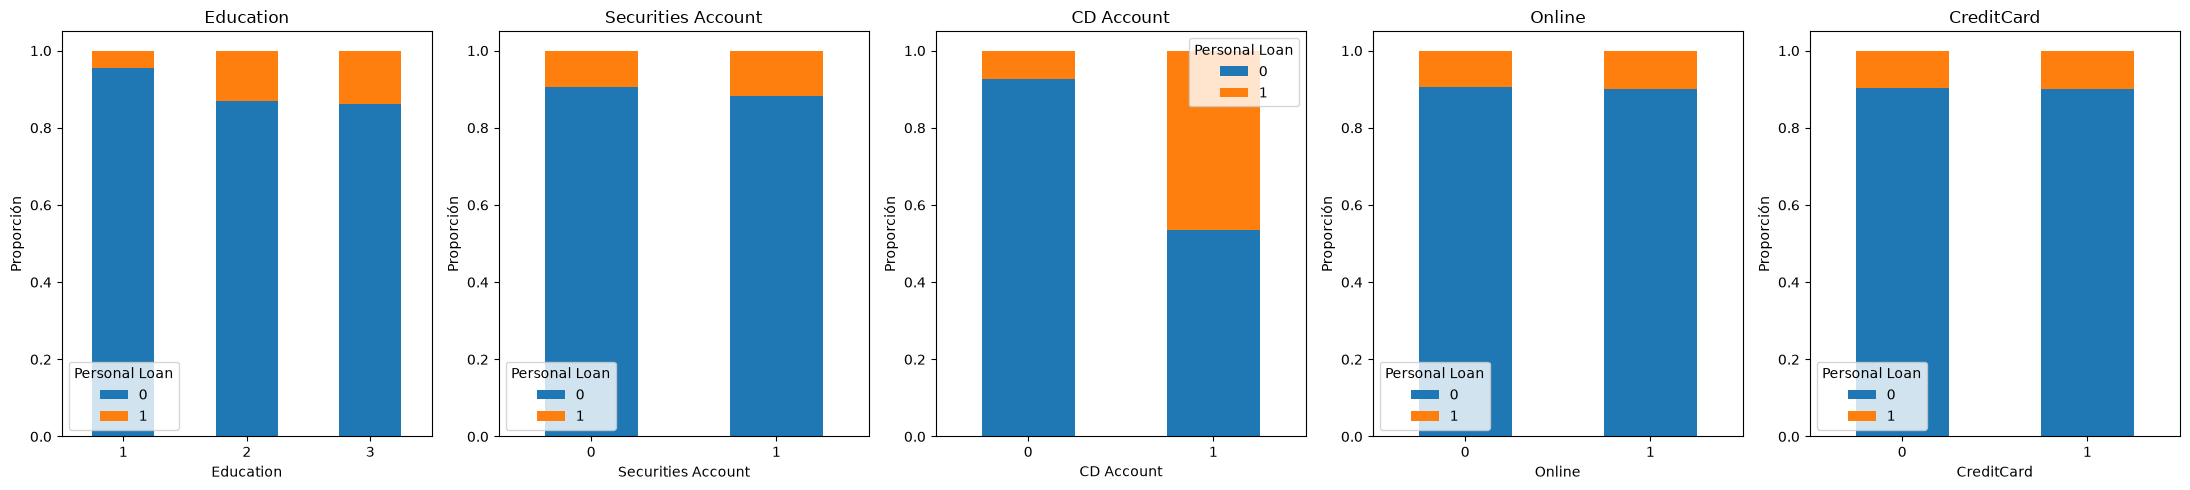

In [28]:
cat_salida = [col for col in cat_cols if col not in ['ZIP Code', 'Personal Loan']]
fig, axes = plt.subplots(1, 5, figsize=(22, 5))
for col, ax in zip(cat_salida, axes):
    pd.crosstab(loan_df[col], loan_df['Personal Loan'], normalize='index').plot(kind='bar', stacked=True, ax=ax, rot=0, title=col)
    ax.set_ylabel('Proporción')
plt.tight_layout()
plt.show()

In [29]:
# Porcentaje de aceptación del préstamo dentro de cada categoría
for col in cat_salida:
    print((pd.crosstab(loan_df[col], loan_df['Personal Loan'], normalize='index') * 100).round(1), '\n')

Personal Loan     0     1
Education                
1              95.5   4.5
2              86.9  13.1
3              86.1  13.9 

Personal Loan          0     1
Securities Account            
0                   90.5   9.5
1                   88.3  11.7 

Personal Loan     0     1
CD Account               
0              92.7   7.3
1              53.5  46.5 

Personal Loan     0    1
Online                  
0              90.6  9.4
1              90.1  9.9 

Personal Loan     0    1
CreditCard              
0              90.4  9.6
1              90.2  9.8 



variables numericas: lo mas claro esta en Income, la mediana de los que aceptaron el prestamo es 142 mil contra 59 mil de los que no, y las cajas ni se tocan (el Q1 de los que aceptaron es 122 mil y el Q3 de los que no es 84 mil), ningun cliente que gana menos de 60 mil acepto, CCAvg va igual (mediana de 3.8 contra 1.4 mil al mes) y tiene sentido porque esta correlacionada con el ingreso, los que aceptaron tambien tienen familias un poco mas grandes (mediana de 3 contra 2) y en Mortgage las dos medianas son 0 pero la caja de los que aceptaron sube mas, Age y Experience tienen cajas casi iguales en los dos grupos asi que no parece que influyan

variables categoricas: lo mas fuerte esta en CD Account, el 46.5% de los que tienen cuenta de certificado de deposito acepto el prestamo contra solo 7.3% de los que no la tienen, en Education los de nivel 1 (graduado) aceptan mucho menos (4.5%) que los de nivel 2 y 3 (13.1% y 13.9%), en Online y CreditCard las barras son casi iguales (entre 9.4% y 9.9% en las dos categorias) y en Securities Account la diferencia es chica (11.7% contra 9.5%), asi que esas tres no parecen tener mucha relacion con aceptar el prestamo

---

**Declaración de uso de IA**

*   Anthropic. (2026). *Claude (Opus 5.5)* [Modelo de lenguaje grande], utilizado para edición de código, depuración y mejora de las interpretaciones. https://claude.ai/

---